In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
data_path = "/content/drive/MyDrive/AutoSenseAI/data/vehicle_maintenance_data.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (50000, 20)


,Vehicle_Model,Mileage,Maintenance_History,Reported_Issues,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Odometer_Reading,Last_Service_Date,Warranty_Expiry_Date,Owner_Type,Insurance_Premium,Service_History,Accident_History,Fuel_Efficiency,Tire_Condition,Brake_Condition,Battery_Status,Need_Maintenance
0,Truck,58765,Good,0,4,Electric,Automatic,2000,28524,2023-11-23,2025-06-24,Second,20782,6,3,13.622204,New,New,Weak,1
1,Van,60353,Average,1,7,Electric,Automatic,2500,133630,2023-09-21,2025-06-04,Second,23489,7,0,13.625307,New,New,Weak,1
2,Bus,68072,Poor,0,2,Electric,Automatic,1500,34022,2023-06-27,2025-04-27,First,17979,7,0,14.306302,New,Good,Weak,1
3,Bus,60849,Average,4,5,Petrol,Automatic,2500,81636,2023-08-24,2025-11-05,Second,6220,7,3,18.709467,New,Worn Out,New,1
4,Bus,45742,Poor,5,1,Petrol,Manual,2000,97162,2023-05-25,2025-09-14,Third,16446,6,2,16.977482,Good,Good,Weak,1


In [4]:
print(df.columns.tolist())

['Vehicle_Model', 'Mileage', 'Maintenance_History', 'Reported_Issues', 'Vehicle_Age', 'Fuel_Type', 'Transmission_Type', 'Engine_Size', 'Odometer_Reading', 'Last_Service_Date', 'Warranty_Expiry_Date', 'Owner_Type', 'Insurance_Premium', 'Service_History', 'Accident_History', 'Fuel_Efficiency', 'Tire_Condition', 'Brake_Condition', 'Battery_Status', 'Need_Maintenance']


In [5]:
target = "Need_Maintenance"

print(df[target].value_counts())
print()
print(df[target].value_counts(normalize=True))

Need_Maintenance
1    40498
0     9502
Name: count, dtype: int64

Need_Maintenance
1    0.80996
0    0.19004
Name: proportion, dtype: float64


In [6]:
print("Unique target values:", df[target].unique())

Unique target values: [1 0]


In [7]:
df[target] = df[target].astype(int)

In [8]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
Vehicle_Model           0
Mileage                 0
Maintenance_History     0
Reported_Issues         0
Vehicle_Age             0
Fuel_Type               0
Transmission_Type       0
Engine_Size             0
Odometer_Reading        0
Last_Service_Date       0
Warranty_Expiry_Date    0
Owner_Type              0
Insurance_Premium       0
Service_History         0
Accident_History        0
Fuel_Efficiency         0
Tire_Condition          0
Brake_Condition         0
Battery_Status          0
Need_Maintenance        0
dtype: int64

Duplicate rows: 0


In [9]:
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (50000, 20)


In [10]:
basic_features = [
    "Vehicle_Model",
    "Mileage",
    "Vehicle_Age",
    "Fuel_Type",
    "Transmission_Type",
    "Engine_Size",
    "Reported_Issues"
]

enriched_features = basic_features + [
    "Maintenance_History",
    "Service_History",
    "Accident_History",
    "Tire_Condition",
    "Brake_Condition",
    "Battery_Status"
]

print("Basic features:")
print(basic_features)

print("\nEnriched features:")
print(enriched_features)

Basic features:
['Vehicle_Model', 'Mileage', 'Vehicle_Age', 'Fuel_Type', 'Transmission_Type', 'Engine_Size', 'Reported_Issues']

Enriched features:
['Vehicle_Model', 'Mileage', 'Vehicle_Age', 'Fuel_Type', 'Transmission_Type', 'Engine_Size', 'Reported_Issues', 'Maintenance_History', 'Service_History', 'Accident_History', 'Tire_Condition', 'Brake_Condition', 'Battery_Status']


In [11]:
df[basic_features].head()

,Vehicle_Model,Mileage,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Reported_Issues
0,Truck,58765,4,Electric,Automatic,2000,0
1,Van,60353,7,Electric,Automatic,2500,1
2,Bus,68072,2,Electric,Automatic,1500,0
3,Bus,60849,5,Petrol,Automatic,2500,4
4,Bus,45742,1,Petrol,Manual,2000,5


In [12]:
df[enriched_features].head()

,Vehicle_Model,Mileage,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Reported_Issues,Maintenance_History,Service_History,Accident_History,Tire_Condition,Brake_Condition,Battery_Status
0,Truck,58765,4,Electric,Automatic,2000,0,Good,6,3,New,New,Weak
1,Van,60353,7,Electric,Automatic,2500,1,Average,7,0,New,New,Weak
2,Bus,68072,2,Electric,Automatic,1500,0,Poor,7,0,New,Good,Weak
3,Bus,60849,5,Petrol,Automatic,2500,4,Average,7,3,New,Worn Out,New
4,Bus,45742,1,Petrol,Manual,2000,5,Poor,6,2,Good,Good,Weak


In [13]:
print(df[enriched_features].dtypes)

Vehicle_Model          object
Mileage                 int64
Vehicle_Age             int64
Fuel_Type              object
Transmission_Type      object
Engine_Size             int64
Reported_Issues         int64
Maintenance_History    object
Service_History         int64
Accident_History        int64
Tire_Condition         object
Brake_Condition        object
Battery_Status         object
dtype: object


In [14]:
X_basic = df[basic_features].copy()
X_enriched = df[enriched_features].copy()

y = df[target].copy()

In [15]:
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_basic_train = X_basic.iloc[train_idx]
X_basic_test = X_basic.iloc[test_idx]

X_enriched_train = X_enriched.iloc[train_idx]
X_enriched_test = X_enriched.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

Training samples: 40000
Testing samples: 10000


In [16]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
Need_Maintenance
1    0.80995
0    0.19005
Name: proportion, dtype: float64

Testing target distribution:
Need_Maintenance
1    0.81
0    0.19
Name: proportion, dtype: float64


In [17]:
def build_preprocessor(dataframe, feature_columns):
    categorical_columns = [
        col for col in feature_columns
        if dataframe[col].dtype == "object"
    ]

    numerical_columns = [
        col for col in feature_columns
        if col not in categorical_columns
    ]

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ])

    numerical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ])

    preprocessor = ColumnTransformer([
        (
            "categorical",
            categorical_pipeline,
            categorical_columns
        ),
        (
            "numerical",
            numerical_pipeline,
            numerical_columns
        )
    ])

    return preprocessor, categorical_columns, numerical_columns

In [18]:
basic_preprocessor, basic_cat, basic_num = build_preprocessor(
    df,
    basic_features
)

print("Basic categorical:")
print(basic_cat)

print("\nBasic numerical:")
print(basic_num)

Basic categorical:
['Vehicle_Model', 'Fuel_Type', 'Transmission_Type']

Basic numerical:
['Mileage', 'Vehicle_Age', 'Engine_Size', 'Reported_Issues']


In [19]:
enriched_preprocessor, enriched_cat, enriched_num = build_preprocessor(
    df,
    enriched_features
)

print("Enriched categorical:")
print(enriched_cat)

print("\nEnriched numerical:")
print(enriched_num)

Enriched categorical:
['Vehicle_Model', 'Fuel_Type', 'Transmission_Type', 'Maintenance_History', 'Tire_Condition', 'Brake_Condition', 'Battery_Status']

Enriched numerical:
['Mileage', 'Vehicle_Age', 'Engine_Size', 'Reported_Issues', 'Service_History', 'Accident_History']


In [20]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("scale_pos_weight:", round(scale_pos_weight, 3))

Negative samples: 7602
Positive samples: 32398
scale_pos_weight: 0.235


In [21]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probabilities)
    else:
        probabilities = None
        auc = np.nan

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),
        "ROC_AUC": auc
    }

    return metrics, predictions, probabilities

In [22]:
dummy_pipeline = Pipeline([
    (
        "preprocessor",
        build_preprocessor(df, enriched_features)[0]
    ),
    (
        "classifier",
        DummyClassifier(strategy="most_frequent")
    )
])

dummy_pipeline.fit(
    X_enriched_train,
    y_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Vehicle_Model', 'Fuel_Type',
                                                   'Transmission_Type',
                                                   'Maintenance_History',
                                                   'Tire_Condition',
                                                   'Brake_Condition',
                                                   'Battery_Status']),
                                                 ('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Mileage', 'Vehicle_Age',
                                                   'Engine_Size',
                                                   'Reported_Issues',
                                                   'Service_History',
                                                   'Accident_History'])])),
                ('classifier', DummyClassifier(strategy='most_frequent'))])

In [23]:
dummy_metrics, dummy_pred, dummy_prob = evaluate_model(
    "Dummy Baseline",
    dummy_pipeline,
    X_enriched_test,
    y_test
)

dummy_metrics

{'Model': 'Dummy Baseline',
 'Accuracy': 0.81,
 'Precision': 0.81,
 'Recall': 1.0,
 'F1': 0.8950276243093923,
 'ROC_AUC': np.float64(0.5)}

In [24]:
basic_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [25]:
basic_xgb_pipeline = Pipeline([
    (
        "preprocessor",
        build_preprocessor(df, basic_features)[0]
    ),
    (
        "classifier",
        basic_xgb
    )
])

In [26]:
basic_xgb_pipeline.fit(
    X_basic_train,
    y_train
)

print("Basic XGBoost training complete.")

Basic XGBoost training complete.


In [27]:
basic_metrics, basic_pred, basic_prob = evaluate_model(
    "Basic XGBoost",
    basic_xgb_pipeline,
    X_basic_test,
    y_test
)

basic_metrics

{'Model': 'Basic XGBoost',
 'Accuracy': 0.6493,
 'Precision': 0.9493249853257679,
 'Recall': 0.5990123456790123,
 'F1': 0.7345393989856938,
 'ROC_AUC': np.float64(0.7764699805068227)}

In [28]:
print(
    classification_report(
        y_test,
        basic_pred,
        target_names=[
            "No Maintenance",
            "Maintenance Required"
        ],
        zero_division=0
    )
)

                      precision    recall  f1-score   support

      No Maintenance       0.34      0.86      0.48      1900
Maintenance Required       0.95      0.60      0.73      8100

            accuracy                           0.65     10000
           macro avg       0.64      0.73      0.61     10000
        weighted avg       0.83      0.65      0.69     10000



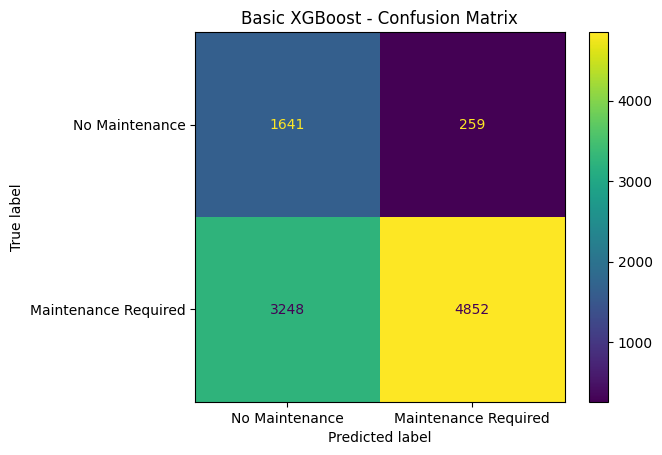

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    basic_pred,
    display_labels=[
        "No Maintenance",
        "Maintenance Required"
    ]
)

plt.title("Basic XGBoost - Confusion Matrix")
plt.show()

In [30]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [31]:
rf_pipeline = Pipeline([
    (
        "preprocessor",
        build_preprocessor(df, enriched_features)[0]
    ),
    (
        "classifier",
        rf_model
    )
])

In [32]:
rf_pipeline.fit(
    X_enriched_train,
    y_train
)

print("Random Forest training complete.")

Random Forest training complete.


In [33]:
rf_metrics, rf_pred, rf_prob = evaluate_model(
    "Enriched Random Forest",
    rf_pipeline,
    X_enriched_test,
    y_test
)

rf_metrics

{'Model': 'Enriched Random Forest',
 'Accuracy': 1.0,
 'Precision': 1.0,
 'Recall': 1.0,
 'F1': 1.0,
 'ROC_AUC': np.float64(1.0)}

In [34]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "No Maintenance",
            "Maintenance Required"
        ],
        zero_division=0
    )
)

                      precision    recall  f1-score   support

      No Maintenance       1.00      1.00      1.00      1900
Maintenance Required       1.00      1.00      1.00      8100

            accuracy                           1.00     10000
           macro avg       1.00      1.00      1.00     10000
        weighted avg       1.00      1.00      1.00     10000



In [35]:
enriched_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [36]:
enriched_xgb_pipeline = Pipeline([
    (
        "preprocessor",
        build_preprocessor(df, enriched_features)[0]
    ),
    (
        "classifier",
        enriched_xgb
    )
])

In [37]:
enriched_xgb_pipeline.fit(
    X_enriched_train,
    y_train
)

print("Enriched XGBoost training complete.")

Enriched XGBoost training complete.


In [38]:
enriched_metrics, enriched_pred, enriched_prob = evaluate_model(
    "Enriched XGBoost",
    enriched_xgb_pipeline,
    X_enriched_test,
    y_test
)

enriched_metrics

{'Model': 'Enriched XGBoost',
 'Accuracy': 1.0,
 'Precision': 1.0,
 'Recall': 1.0,
 'F1': 1.0,
 'ROC_AUC': np.float64(1.0)}

In [39]:
print(
    classification_report(
        y_test,
        enriched_pred,
        target_names=[
            "No Maintenance",
            "Maintenance Required"
        ],
        zero_division=0
    )
)

                      precision    recall  f1-score   support

      No Maintenance       1.00      1.00      1.00      1900
Maintenance Required       1.00      1.00      1.00      8100

            accuracy                           1.00     10000
           macro avg       1.00      1.00      1.00     10000
        weighted avg       1.00      1.00      1.00     10000



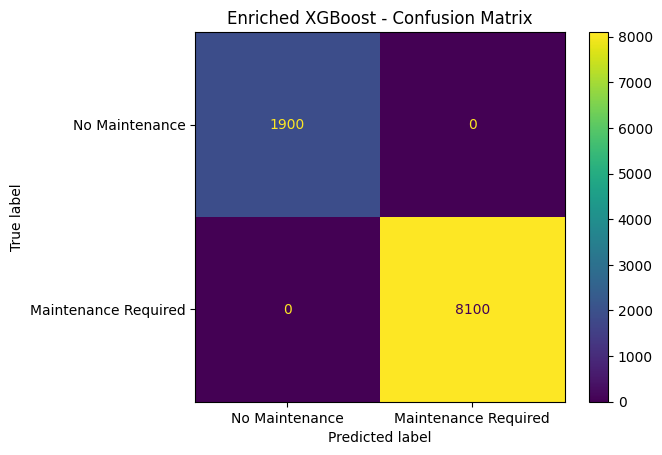

In [40]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    enriched_pred,
    display_labels=[
        "No Maintenance",
        "Maintenance Required"
    ]
)

plt.title("Enriched XGBoost - Confusion Matrix")
plt.show()

In [41]:
comparison_df = pd.DataFrame([
    dummy_metrics,
    basic_metrics,
    rf_metrics,
    enriched_metrics
])

comparison_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy Baseline,0.8100,0.810000,1.000000,0.895028,0.50000
1,Basic XGBoost,0.6493,0.949325,0.599012,0.734539,0.77647
2,Enriched Random Forest,1.0000,1.000000,1.000000,1.000000,1.00000
3,Enriched XGBoost,1.0000,1.000000,1.000000,1.000000,1.00000


In [42]:
comparison_percent = comparison_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC"
]

for col in metric_columns:
    comparison_percent[col] = (
        comparison_percent[col] * 100
    ).round(2)

comparison_percent

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Dummy Baseline,81.00,81.00,100.0,89.50,50.00
1,Basic XGBoost,64.93,94.93,59.9,73.45,77.65
2,Enriched Random Forest,100.00,100.00,100.0,100.00,100.00
3,Enriched XGBoost,100.00,100.00,100.0,100.00,100.00


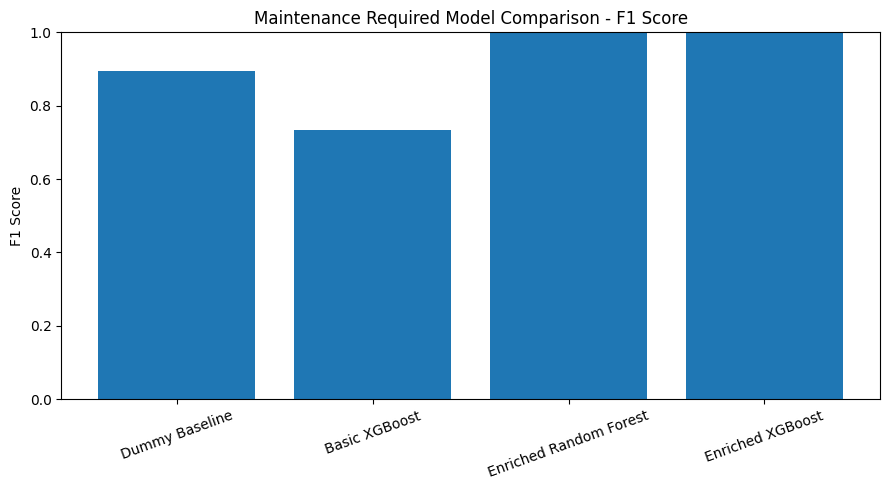

In [43]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["F1"]
)

plt.title("Maintenance Required Model Comparison - F1 Score")
plt.ylabel("F1 Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

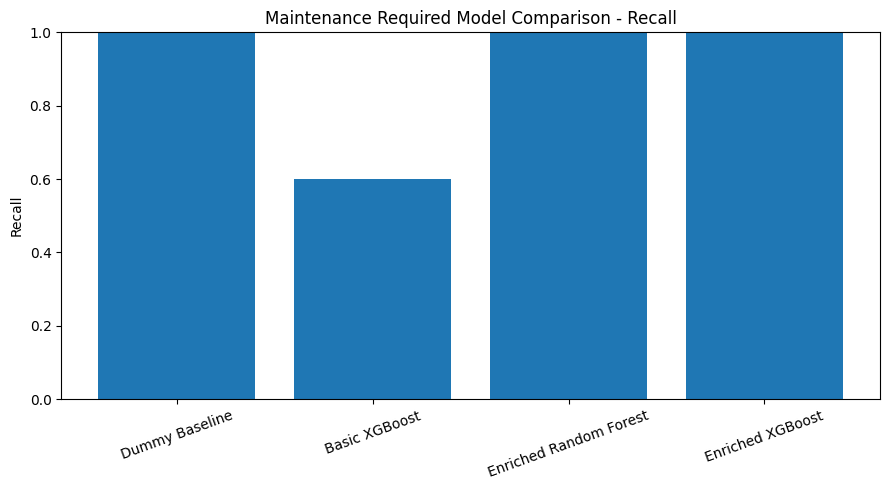

In [44]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Recall"]
)

plt.title("Maintenance Required Model Comparison - Recall")
plt.ylabel("Recall")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [45]:
comparison_sorted = comparison_df.sort_values(
    by="F1",
    ascending=False
)

comparison_sorted

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
3,Enriched XGBoost,1.0000,1.000000,1.000000,1.000000,1.00000
2,Enriched Random Forest,1.0000,1.000000,1.000000,1.000000,1.00000
0,Dummy Baseline,0.8100,0.810000,1.000000,0.895028,0.50000
1,Basic XGBoost,0.6493,0.949325,0.599012,0.734539,0.77647


In [46]:
best_model_name = comparison_sorted.iloc[0]["Model"]
best_f1 = comparison_sorted.iloc[0]["F1"]

print("Best model by F1:", best_model_name)
print("Best F1:", round(best_f1, 4))

Best model by F1: Enriched XGBoost
Best F1: 1.0


In [47]:
basic_f1 = basic_metrics["F1"]
enriched_f1 = enriched_metrics["F1"]

basic_recall = basic_metrics["Recall"]
enriched_recall = enriched_metrics["Recall"]

print(
    "F1 improvement:",
    round(
        (enriched_f1 - basic_f1) * 100,
        2
    ),
    "percentage points"
)

print(
    "Recall improvement:",
    round(
        (enriched_recall - basic_recall) * 100,
        2
    ),
    "percentage points"
)

F1 improvement: 26.55 percentage points
Recall improvement: 40.1 percentage points


In [48]:
results_dir = "/content/drive/MyDrive/AutoSenseAI/results"

os.makedirs(
    results_dir,
    exist_ok=True
)

In [49]:
comparison_df.to_csv(
    os.path.join(
        results_dir,
        "maintenance_need_v2_comparison.csv"
    ),
    index=False
)

print("Comparison CSV saved.")

Comparison CSV saved.


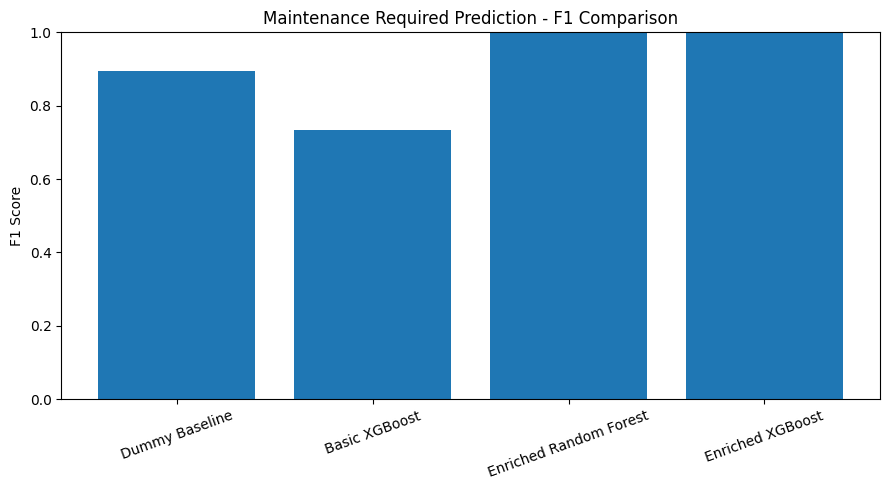

Saved: /content/drive/MyDrive/AutoSenseAI/results/maintenance_need_v2_f1_comparison.png


In [50]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["F1"]
)

plt.title("Maintenance Required Prediction - F1 Comparison")
plt.ylabel("F1 Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()

f1_path = os.path.join(
    results_dir,
    "maintenance_need_v2_f1_comparison.png"
)

plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", f1_path)

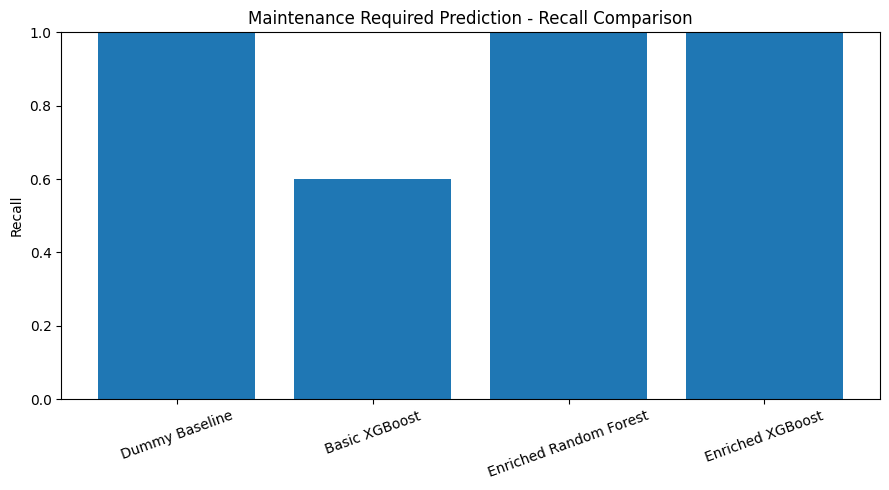

Saved: /content/drive/MyDrive/AutoSenseAI/results/maintenance_need_v2_recall_comparison.png


In [51]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Recall"]
)

plt.title("Maintenance Required Prediction - Recall Comparison")
plt.ylabel("Recall")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()

recall_path = os.path.join(
    results_dir,
    "maintenance_need_v2_recall_comparison.png"
)

plt.savefig(
    recall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", recall_path)

In [52]:
model_dir = "/content/drive/MyDrive/AutoSenseAI/models"

os.makedirs(
    model_dir,
    exist_ok=True
)

In [53]:
basic_model_path = os.path.join(
    model_dir,
    "maintenance_need_v2_basic_xgboost.pkl"
)

joblib.dump(
    basic_xgb_pipeline,
    basic_model_path
)

print("Saved Basic model:", basic_model_path)

Saved Basic model: /content/drive/MyDrive/AutoSenseAI/models/maintenance_need_v2_basic_xgboost.pkl


In [54]:
enriched_model_path = os.path.join(
    model_dir,
    "maintenance_need_v2_enriched_xgboost.pkl"
)

joblib.dump(
    enriched_xgb_pipeline,
    enriched_model_path
)

print("Saved Enriched model:", enriched_model_path)

Saved Enriched model: /content/drive/MyDrive/AutoSenseAI/models/maintenance_need_v2_enriched_xgboost.pkl


In [55]:
rf_model_path = os.path.join(
    model_dir,
    "maintenance_need_v2_enriched_random_forest.pkl"
)

joblib.dump(
    rf_pipeline,
    rf_model_path
)

print("Saved RF model:", rf_model_path)

Saved RF model: /content/drive/MyDrive/AutoSenseAI/models/maintenance_need_v2_enriched_random_forest.pkl


In [56]:
sample_basic = X_basic_test.iloc[[0]]

sample_basic

,Vehicle_Model,Mileage,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Reported_Issues
46311,SUV,69301,5,Electric,Manual,1000,3


In [57]:
basic_prediction = basic_xgb_pipeline.predict(
    sample_basic
)[0]

basic_probability = basic_xgb_pipeline.predict_proba(
    sample_basic
)[0]

print("Predicted class:", basic_prediction)
print("No Maintenance score:", round(basic_probability[0], 4))
print("Maintenance Required score:", round(basic_probability[1], 4))

print(
    "Actual class:",
    y_test.iloc[0]
)

Predicted class: 1
No Maintenance score: 0.3641
Maintenance Required score: 0.6359
Actual class: 1


In [58]:
sample_enriched = X_enriched_test.iloc[[0]]

sample_enriched

,Vehicle_Model,Mileage,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Reported_Issues,Maintenance_History,Service_History,Accident_History,Tire_Condition,Brake_Condition,Battery_Status
46311,SUV,69301,5,Electric,Manual,1000,3,Average,2,1,Worn Out,New,Weak


In [59]:
enriched_prediction = enriched_xgb_pipeline.predict(
    sample_enriched
)[0]

enriched_probability = enriched_xgb_pipeline.predict_proba(
    sample_enriched
)[0]

print("Predicted class:", enriched_prediction)
print("No Maintenance score:", round(enriched_probability[0], 4))
print("Maintenance Required score:", round(enriched_probability[1], 4))

print(
    "Actual class:",
    y_test.iloc[0]
)

Predicted class: 1
No Maintenance score: 0.0
Maintenance Required score: 1.0
Actual class: 1


In [60]:
classifier = enriched_xgb_pipeline.named_steps["classifier"]

print(
    "Classifier classes:",
    classifier.classes_
)

Classifier classes: [0 1]


In [61]:
preprocessor = enriched_xgb_pipeline.named_steps["preprocessor"]
classifier = enriched_xgb_pipeline.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
22,categorical__Battery_Status_Weak,0.235841
19,categorical__Brake_Condition_Worn Out,0.232350
26,numerical__Reported_Issues,0.114697
17,categorical__Brake_Condition_Good,0.101555
18,categorical__Brake_Condition_New,0.075924
12,categorical__Maintenance_History_Good,0.055994
28,numerical__Accident_History,0.052802
13,categorical__Maintenance_History_Poor,0.050773
21,categorical__Battery_Status_New,0.031360
27,numerical__Service_History,0.028011


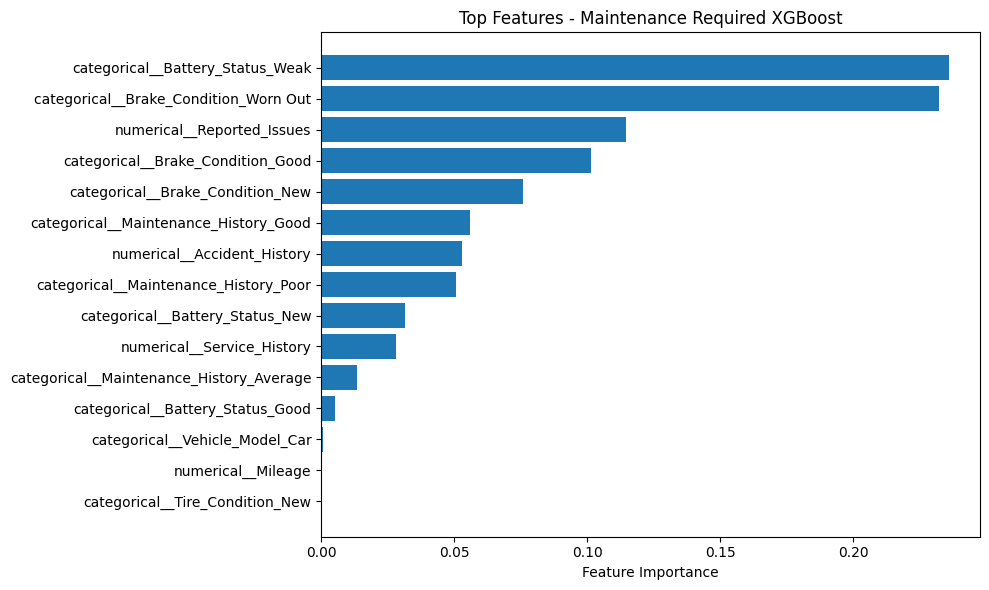

In [62]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top Features - Maintenance Required XGBoost")
plt.xlabel("Feature Importance")

plt.tight_layout()
plt.show()

## Experiment Summary

Objective:
Develop a realistic Maintenance Required classifier that uses progressively
enriched vehicle and service-center information.

Target:
Need_Maintenance

Basic Input Features:
- Vehicle Model
- Mileage
- Vehicle Age
- Fuel Type
- Transmission Type
- Engine Size
- Reported Issues

Enriched Inputs:
- Basic features
- Maintenance History
- Service History
- Accident History
- Tire Condition
- Brake Condition
- Battery Status

Compared Models:
- Dummy majority-class baseline
- Basic XGBoost
- Enriched Random Forest
- Enriched XGBoost

Evaluation Metrics:
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC

Primary Evaluation Consideration:
F1 and Recall are emphasized because the dataset is imbalanced and false
negative maintenance decisions are important.

Final Results:
[Insert actual results here]

Selected Model:
[Insert actual selected model]

Limitation:
The current dataset may contain synthetic or strongly structured relationships.
Therefore held-out dataset performance should not be interpreted as guaranteed
real-world vehicle-service-center accuracy.